---
## Projet Speed Dating

<b>Objectif:</b> Ce projet procède à `l'analyse exploratoire` des données collectées lors des speed datings (2002-2004) meneés par Columbia University pour identifier les facteurs qui influencent la décision d'un like et d'un match entre deux personnes. Nous répondrons aux questions clés en nous appuyant sur des statistiques descriptives et des visualisations.

<b>Données personnelles et conformité RGPD:</b>
Le jeu de données contient des informations personnelles, dont certaines sensibles au sens du RGPD (origine raciale, âge, genre). Avant toute analyse, on relève que ces données sont déjà pseudonymisées : chaque participant n'est identifié que par un numéro (`iid`), sans nom ni coordonnée. Elles sont exploitées ici à des fins d'analyse statistique uniquement, de manière agrégée, sans chercher à réidentifier une personne.

---
## 1. Imports

In [1]:
# Importation des bibliothèques
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px
from plotly.subplots import make_subplots
import plotly.graph_objects as go
from scipy import stats

pd.options.display.max_columns = None

---
## 2. Chargement du dataset

In [2]:
# Chargement du fichier CSV
df = pd.read_csv('data/Speed+Dating+Data.csv', encoding='latin-1')

# Affichage des dimensions du dataset
print(f"Le Dataset contient {df.shape[0]} lignes et {df.shape[1]} colonnes.")

# Aperçu du dataset
df.head(10)

Le Dataset contient 8378 lignes et 195 colonnes.


,iid,id,gender,idg,condtn,wave,round,position,positin1,order,partner,pid,match,int_corr,samerace,age_o,race_o,pf_o_att,pf_o_sin,pf_o_int,pf_o_fun,pf_o_amb,pf_o_sha,dec_o,attr_o,sinc_o,intel_o,fun_o,amb_o,shar_o,like_o,prob_o,met_o,age,field,field_cd,undergra,mn_sat,tuition,race,imprace,imprelig,from,zipcode,income,goal,date,go_out,career,career_c,sports,tvsports,exercise,dining,museums,art,hiking,gaming,clubbing,reading,tv,theater,movies,concerts,music,shopping,yoga,exphappy,expnum,attr1_1,sinc1_1,intel1_1,fun1_1,amb1_1,shar1_1,attr4_1,sinc4_1,intel4_1,fun4_1,amb4_1,shar4_1,attr2_1,sinc2_1,intel2_1,fun2_1,amb2_1,shar2_1,attr3_1,sinc3_1,fun3_1,intel3_1,amb3_1,attr5_1,sinc5_1,intel5_1,fun5_1,amb5_1,dec,attr,sinc,intel,fun,amb,shar,like,prob,met,match_es,attr1_s,sinc1_s,intel1_s,fun1_s,amb1_s,shar1_s,attr3_s,sinc3_s,intel3_s,fun3_s,amb3_s,satis_2,length,numdat_2,attr7_2,sinc7_2,intel7_2,fun7_2,amb7_2,shar7_2,attr1_2,sinc1_2,intel1_2,fun1_2,amb1_2,shar1_2,attr4_2,sinc4_2,intel4_2,fun4_2,amb4_2,shar4_2,attr2_2,sinc2_2,intel2_2,fun2_2,amb2_2,shar2_2,attr3_2,sinc3_2,intel3_2,fun3_2,amb3_2,attr5_2,sinc5_2,intel5_2,fun5_2,amb5_2,you_call,them_cal,date_3,numdat_3,num_in_3,attr1_3,sinc1_3,intel1_3,fun1_3,amb1_3,shar1_3,attr7_3,sinc7_3,intel7_3,fun7_3,amb7_3,shar7_3,attr4_3,sinc4_3,intel4_3,fun4_3,amb4_3,shar4_3,attr2_3,sinc2_3,intel2_3,fun2_3,amb2_3,shar2_3,attr3_3,sinc3_3,intel3_3,fun3_3,amb3_3,attr5_3,sinc5_3,intel5_3,fun5_3,amb5_3
0,1,1.0,0,1,1,1,10,7,NaN,4,1,11.0,0,0.14,0,27.0,2.0,35.00,20.00,20.00,20.00,0.00,5.00,0,6.0,8.0,8.0,8.0,8.0,6.0,7.0,4.0,2.0,21.0,Law,1.0,NaN,NaN,NaN,4.0,2.0,4.0,Chicago,"60,521","69,487.00",2.0,7.0,1.0,lawyer,NaN,9.0,2.0,8.0,9.0,1.0,1.0,5.0,1.0,5.0,6.0,9.0,1.0,10.0,10.0,9.0,8.0,1.0,3.0,2.0,15.0,20.0,20.0,15.0,15.0,15.0,NaN,NaN,NaN,NaN,NaN,NaN,35.0,20.0,15.0,20.0,5.0,5.0,6.0,8.0,8.0,8.0,7.0,NaN,NaN,NaN,NaN,NaN,1,6.0,9.0,7.0,7.0,6.0,5.0,7.0,6.0,2.0,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.0,2.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,19.44,16.67,13.89,22.22,11.11,16.67,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.0,7.0,8.0,7.0,6.0,NaN,NaN,NaN,NaN,NaN,1.0,1.0,0.0,NaN,NaN,15.0,20.0,20.0,15.0,15.0,15.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0,7.0,7.0,7.0,7.0,NaN,NaN,NaN,NaN,NaN
1,1,1.0,0,1,1,1,10,7,NaN,3,2,12.0,0,0.54,0,22.0,2.0,60.00,0.00,0.00,40.00,0.00,0.00,0,7.0,8.0,10.0,7.0,7.0,5.0,8.0,4.0,2.0,21.0,Law,1.0,NaN,NaN,NaN,4.0,2.0,4.0,Chicago,"60,521","69,487.00",2.0,7.0,1.0,lawyer,NaN,9.0,2.0,8.0,9.0,1.0,1.0,5.0,1.0,5.0,6.0,9.0,1.0,10.0,10.0,9.0,8.0,1.0,3.0,2.0,15.0,20.0,20.0,15.0,15.0,15.0,NaN,NaN,NaN,NaN,NaN,NaN,35.0,20.0,15.0,20.0,5.0,5.0,6.0,8.0,8.0,8.0,7.0,NaN,NaN,NaN,NaN,NaN,1,7.0,8.0,7.0,8.0,5.0,6.0,7.0,5.0,1.0,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.0,2.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,19.44,16.67,13.89,22.22,11.11,16.67,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.0,7.0,8.0,7.0,6.0,NaN,NaN,NaN,NaN,NaN,1.0,1.0,0.0,NaN,NaN,15.0,20.0,20.0,15.0,15.0,15.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0,7.0,7.0,7.0,7.0,NaN,NaN,NaN,NaN,NaN
2,1,1.0,0,1,1,1,10,7,NaN,10,3,13.0,1,0.16,1,22.0,4.0,19.00,18.00,19.00,18.00,14.00,12.00,1,10.0,10.0,10.0,10.0,10.0,10.0,10.0,10.0,1.0,21.0,Law,1.0,NaN,NaN,NaN,4.0,2.0,4.0,Chicago,"60,521","69,487.00",2.0,7.0,1.0,lawyer,NaN,9.0,2.0,8.0,9.0,1.0,1.0,5.0,1.0,5.0,6.0,9.0,1.0,10.0,10.0,9.0,8.0,1.0,3.0,2.0,15.0,20.0,20.0,15.0,15.0,15.0,NaN,NaN,NaN,NaN,NaN,NaN,35.0,20.0,15.0,20.0,5.0,5.0,6.0,8.0,8.0,8.0,7.0,NaN,NaN,NaN,NaN,NaN,1,5.0,8.0,9.0,8.0,5.0,7.0,7.0,NaN,1.0,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.0,2.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,19.44,16.67,13.89,22.22,11.11,16.67,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.0,7.0,8.0,7.0,6.0,NaN,NaN,NaN,NaN,NaN,1.0,1.0,0.0,NaN,NaN,15.0,20.0,20.0,15.0,15.0,15.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0,7.0,7.0,7.0,7.0,NaN,NaN,NaN,NaN,NaN
3,1,1.0,0,1,1,1,10,7,NaN,5,4,14.0,1,0.61,0,23.0,2.0,30.00,5.00,15.00,40.00,5.00,

In [3]:
print("Résumé du dataset:")
print("-------------------------------------------")
df.info()
print("-------------------------------------------")

print(f"Nombre total de participants: {df["pid"].nunique(dropna=False)}")
print(f"Nombre de participants renseignés: {df["iid"].nunique(dropna=False)}")
print(f"Nombre total de dates: {df.groupby("gender")["gender"].count()[1]: .0f}")

Résumé du dataset:
-------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8378 entries, 0 to 8377
Columns: 195 entries, iid to amb5_3
dtypes: float64(174), int64(13), object(8)
memory usage: 12.5+ MB
-------------------------------------------
Nombre total de participants: 552
Nombre de participants renseignés: 551
Nombre total de dates:  4194


In [4]:
df.describe(include='all')

,iid,id,gender,idg,condtn,wave,round,position,positin1,order,partner,pid,match,int_corr,samerace,age_o,race_o,pf_o_att,pf_o_sin,pf_o_int,pf_o_fun,pf_o_amb,pf_o_sha,dec_o,attr_o,sinc_o,intel_o,fun_o,amb_o,shar_o,like_o,prob_o,met_o,age,field,field_cd,undergra,mn_sat,tuition,race,imprace,imprelig,from,zipcode,income,goal,date,go_out,career,career_c,sports,tvsports,exercise,dining,museums,art,hiking,gaming,clubbing,reading,tv,theater,movies,concerts,music,shopping,yoga,exphappy,expnum,attr1_1,sinc1_1,intel1_1,fun1_1,amb1_1,shar1_1,attr4_1,sinc4_1,intel4_1,fun4_1,amb4_1,shar4_1,attr2_1,sinc2_1,intel2_1,fun2_1,amb2_1,shar2_1,attr3_1,sinc3_1,fun3_1,intel3_1,amb3_1,attr5_1,sinc5_1,intel5_1,fun5_1,amb5_1,dec,attr,sinc,intel,fun,amb,shar,like,prob,met,match_es,attr1_s,sinc1_s,intel1_s,fun1_s,amb1_s,shar1_s,attr3_s,sinc3_s,intel3_s,fun3_s,amb3_s,satis_2,length,numdat_2,attr7_2,sinc7_2,intel7_2,fun7_2,amb7_2,shar7_2,attr1_2,sinc1_2,intel1_2,fun1_2,amb1_2,shar1_2,attr4_2,sinc4_2,intel4_2,fun4_2,amb4_2,shar4_2,attr2_2,sinc2_2,intel2_2,fun2_2,amb2_2,shar2_2,attr3_2,sinc3_2,intel3_2,fun3_2,amb3_2,attr5_2,sinc5_2,intel5_2,fun5_2,amb5_2,you_call,them_cal,date_3,numdat_3,num_in_3,attr1_3,sinc1_3,intel1_3,fun1_3,amb1_3,shar1_3,attr7_3,sinc7_3,intel7_3,fun7_3,amb7_3,shar7_3,attr4_3,sinc4_3,intel4_3,fun4_3,amb4_3,shar4_3,attr2_3,sinc2_3,intel2_3,fun2_3,amb2_3,shar2_3,attr3_3,sinc3_3,intel3_3,fun3_3,amb3_3,attr5_3,sinc5_3,intel5_3,fun5_3,amb5_3
count,8378.000000,8377.000000,8378.000000,8378.000000,8378.000000,8378.000000,8378.000000,8378.000000,6532.000000,8378.000000,8378.000000,8368.000000,8378.000000,8220.000000,8378.000000,8274.000000,8305.000000,8289.000000,8289.000000,8289.000000,8280.000000,8271.000000,8249.000000,8378.000000,8166.000000,8091.000000,8072.000000,8018.000000,7656.000000,7302.000000,8128.000000,8060.000000,7993.000000,8283.000000,8315,8296.000000,4914,3133,3583,8315.000000,8299.000000,8299.000000,8299,7314,4279,8299.000000,8281.000000,8299.000000,8289,8240.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8277.000000,1800.000000,8299.000000,8299.000000,8299.000000,8289.000000,8279.000000,8257.000000,6489.000000,6489.000000,6489.000000,6489.000000,6489.000000,6467.000000,8299.000000,8299.000000,8299.000000,8299.000000,8289.000000,8289.000000,8273.000000,8273.000000,8273.000000,8273.000000,8273.000000,4906.000000,4906.000000,4906.000000,4906.000000,4906.000000,8378.000000,8176.000000,8101.000000,8082.000000,8028.000000,7666.000000,7311.000000,8138.000000,8069.000000,8003.000000,7205.000000,4096.000000,4096.000000,4096.000000,4096.000000,4096.000000,4096.000000,4000.00000,4000.000000,4000.000000,4000.000000,4000.000000,7463.000000,7463.000000,7433.000000,1984.000000,1955.000000,1984.000000,1984.000000,1955.000000,1974.000000,7445.000000,7463.000000,7463.000000,7463.000000,7463.000000,7463.000000,5775.000000,5775.000000,5775.000000,5775.000000,5775.000000,5775.000000,5775.000000,5775.00000,5775.000000,5775.000000,5775.000000,5775.000000,7463.000000,7463.000000,7463.000000,7463.000000,7463.000000,4377.000000,4377.000000,4377.000000,4377.000000,4377.000000,3974.000000,3974.000000,3974.000000,1496.000000,668.000000,3974.000000,3974.000000,3974.000000,3974.000000,3974.000000,3974.000000,2016.000000,2016.000000,2016.000000,2016.000000,2016.000000,2016.000000,2959.000000,2959.000000,2959.000000,2959.000000,2959.000000,2959.000000,2959.000000,2959.000000,2959.000000,2959.000000,2959.000000,2016.000000,3974.000000,3974.000000,3974.000000,3974.000000,3974.000000,2016.000000,2016.000000,2016.000000,2016.000000,2016.000000
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,259,NaN,241,68,115,NaN,NaN,NaN,269,409,261,NaN,NaN,NaN,367,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,

In [5]:
# Calcul du taux de remplissage des colonnes du datset
print(f"Le taux global de remplissage du dataset: {df.notnull().mean().mean() * 100: .2f}%\n")

df_fill_percent = df.notnull().mean() * 100

print(f"Liste des colonnes remplies à moins de 30%: \n{df_fill_percent[df_fill_percent < 30].index}\n")
print(f"Liste des colonnes remplies à moins de 40%: \n{df_fill_percent[df_fill_percent < 40].index}\n")
print(f"Liste des colonnes remplies à moins de 50%: \n{df_fill_percent[df_fill_percent < 50].index}")

Le taux global de remplissage du dataset:  73.56%

Liste des colonnes remplies à moins de 30%: 
Index(['expnum', 'attr7_2', 'sinc7_2', 'intel7_2', 'fun7_2', 'amb7_2',
       'shar7_2', 'numdat_3', 'num_in_3', 'attr7_3', 'sinc7_3', 'intel7_3',
       'fun7_3', 'amb7_3', 'shar7_3', 'shar2_3', 'attr5_3', 'sinc5_3',
       'intel5_3', 'fun5_3', 'amb5_3'],
      dtype='object')

Liste des colonnes remplies à moins de 40%: 
Index(['mn_sat', 'expnum', 'attr7_2', 'sinc7_2', 'intel7_2', 'fun7_2',
       'amb7_2', 'shar7_2', 'numdat_3', 'num_in_3', 'attr7_3', 'sinc7_3',
       'intel7_3', 'fun7_3', 'amb7_3', 'shar7_3', 'attr4_3', 'sinc4_3',
       'intel4_3', 'fun4_3', 'amb4_3', 'shar4_3', 'attr2_3', 'sinc2_3',
       'intel2_3', 'fun2_3', 'amb2_3', 'shar2_3', 'attr5_3', 'sinc5_3',
       'intel5_3', 'fun5_3', 'amb5_3'],
      dtype='object')

Liste des colonnes remplies à moins de 50%: 
Index(['mn_sat', 'tuition', 'expnum', 'attr1_s', 'sinc1_s', 'intel1_s',
       'fun1_s', 'amb1_s', 'shar1_s',

---
## 3. Nettoyage des données & Exploration initiale


In [6]:
# Vérification de l'absence de doublons
print(f"Nombre de lignes en double : {df.duplicated().sum()}")

# Transformation de la variable 'gender' (0/1) en libellés homme/femme
df['gender'] = df['gender'].apply(lambda x: 'Femme' if x == 0 else 'Homme')

Nombre de lignes en double : 0


In [7]:
# Dans certaines colonnes, il y a deux systèmes de notataions: sur 100 et sur 10
# Nécessité d'avoir un seul système de notation
# Les vagues 6,7,8,9 sont sur 10 --> On va les répartir sur 100
def scaling_waves_100(df, waves, attributes):
    # Filtre les lignes correspondant aux waves demandées
    mask = df["wave"].isin(waves)

    # Calcul de la somme par ligne (axis=1) pour les attributs cibles
    denom = df.loc[mask, attributes].sum(axis=1)
    
    # Scaling
    df.loc[mask, attributes] = (
        df.loc[mask, attributes].div(denom, axis=0) * 100
    )

    return df

# Fonction de check de la mise en échelle
def scaling_waves_100_check(df, waves, attributes):
    mask = df["wave"].isin(waves)

    denom = df.loc[mask, attributes].sum(axis=1)
    
    # Vérifier que la somme = 100
    for item in denom:
        if item != 0 and (item > 100.2 or item < 99.8):
            print(f"NOK, {item}")

In [8]:
attrib4_1 = ["attr4_1", "sinc4_1", "intel4_1", "fun4_1", "amb4_1", "shar4_1"]
attrib4_2 = ["attr4_2", "sinc4_2", "intel4_2", "fun4_2", "amb4_2", "shar4_2"]
attrib4_3 = ["attr4_3", "sinc4_3", "intel4_3", "fun4_3", "amb4_3", "shar4_3"]
attrib2_3 = ["attr2_3", "sinc2_3", "intel2_3", "fun2_3", "amb2_3", "shar2_3"]
waves = [6,7,8,9]

# Utilisation d'un même système de notation
df = scaling_waves_100(df, waves, attrib4_1)
df = scaling_waves_100(df, waves, attrib4_2)
df = scaling_waves_100(df, waves, attrib4_3)
df = scaling_waves_100(df, waves, attrib2_3)

# Checker que la mise en échelle est correctement faîte
scaling_waves_100_check(df, waves, attrib4_1)
scaling_waves_100_check(df, waves, attrib4_2)
scaling_waves_100_check(df, waves, attrib4_3)
scaling_waves_100_check(df, waves, attrib2_3)


In [9]:
# Examiner la propotion homme/femme de l'ensemble des participants
nbr_hommes = df.groupby("gender")["pid"].nunique(dropna=False)["Femme"]
nbr_femmmes = df.groupby("gender")["pid"].nunique(dropna=False)["Homme"]
print(f"552 participant: {nbr_hommes} hommes + {nbr_femmmes} femmes")

552 participant: 277 hommes + 275 femmes


La proportion homme/femme est de ~ 50%-50%

In [10]:
# Se sont-ils recontrés auparavant?
display(df["met_o"].value_counts(dropna=False) * 100 / len(df))
display(df["met"].value_counts(dropna=False) * 100 / len(df))

met_o
2.0    91.131535
NaN     4.595369
1.0     4.177608
7.0     0.035808
5.0     0.023872
3.0     0.011936
6.0     0.011936
8.0     0.011936
Name: count, dtype: float64

met
0.0    48.305085
2.0    42.933874
NaN     4.476009
1.0     4.189544
7.0     0.035808
5.0     0.023872
3.0     0.011936
8.0     0.011936
6.0     0.011936
Name: count, dtype: float64

91% des participants ne se sont pas rencontrés avant l'expérience. 4% des participants se sont déjà rencontrés.

On peut dire qu'en général, les notations étaient basées sur le moment présent.

In [11]:
# Vérifier que le flag match est correctement reporté
mask = df['match'] == (df['dec'] * df['dec_o'])
mask.value_counts(dropna=False)

True    8378
Name: count, dtype: int64

Le flag match est correctement renseigné dans tout le dataset: `match == dec & dec_o`

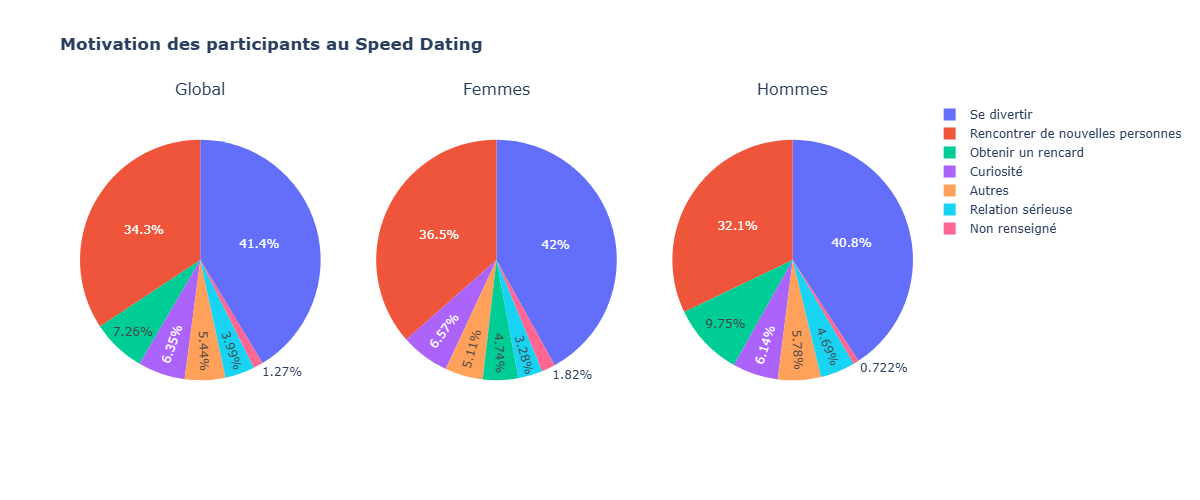

In [12]:
# Découvrir la mativation des participants
goal_labels = {
    1: "Se divertir",
    2: "Rencontrer de nouvelles personnes",
    3: "Obtenir un rencard",
    4: "Relation sérieuse",
    5: "Curiosité",
    6: "Autres",
}

# Motivation globale
df_goal = df[['iid', 'goal']].drop_duplicates()
df_goal = df_goal["goal"].value_counts(dropna=False).reset_index()
df_goal['goal_label'] = df_goal['goal'].map(goal_labels).fillna("Non renseigné")

# Motivation des femmes
df_women = df.loc[df["gender"] == 'Femme',:].reset_index()
df_goal_women = df_women[['iid', 'goal']].drop_duplicates()
df_goal_women = df_goal_women["goal"].value_counts(dropna=False).reset_index()
df_goal_women['goal_label'] = df_goal_women['goal'].map(goal_labels).fillna("Non renseigné")

# Motivation des hommes
df_men = df.loc[df["gender"] == 'Homme',:].reset_index()
df_goal_men = df_men[['iid', 'goal']].drop_duplicates()
df_goal_men = df_goal_men["goal"].value_counts(dropna=False).reset_index()
df_goal_men['goal_label'] = df_goal_men['goal'].map(goal_labels).fillna("Non renseigné")

# Affichage des pourcentages (pie plots)
fig = make_subplots(
    rows=1,
    cols=3,
    specs=[[{"type": "domain"}, {"type": "domain"}, {"type": "domain"}]],
    subplot_titles=["Global", "Femmes", "Hommes"],
)

fig.add_pie(
    labels=df_goal["goal_label"],
    values=df_goal["count"],
    name="Global",
    row=1,
    col=1,
)

fig.add_pie(
    labels=df_goal_women["goal_label"],
    values=df_goal_women["count"],
    name="Femmes",
    row=1,
    col=2,
)

fig.add_pie(
    labels=df_goal_men["goal_label"],
    values=df_goal_men["count"],
    name="Hommes",
    row=1,
    col=3,
)

fig.update_layout(
    title_text="<b>Motivation des participants au Speed Dating</b>",
    height=500,
    width=1200,
)

fig.show(renderer="png")

78.5% des femmes et 73% des hommes ont fait l'expérience juste pour s'amuser ou rencontrer de nouvelles personnes.

10% des femmes et 15% des hommes l'ont fait pour avoir une relation sérieuse ou un date.

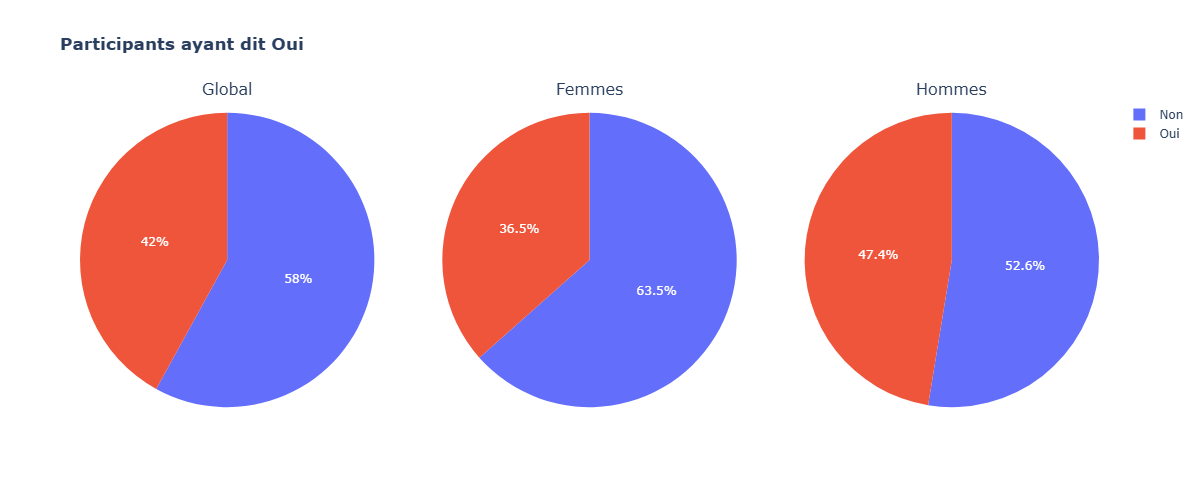

In [13]:
# Combien se sont dit oui? Combien de match?
decision_labels = {
    0: "Non",
    1: "Oui"
}

df_match = df["match"].value_counts().reset_index()
df_match['match_label'] = df_match['match'].map(decision_labels).fillna("Non renseigné")
fig = px.pie(df_match, names="match_label", values ="count", title="<b>Combien se sont dit oui (un match)?</b>")
fig.show()

# Combien ont dit oui?
df_decision = df["dec"].value_counts(dropna=False).reset_index()
df_decision['decision_label'] = df_decision['dec'].map(decision_labels).fillna("Non renseigné")

df_decision_men = df_men["dec"].value_counts(dropna=False).reset_index()
df_decision_men['decision_label'] = df_decision_men['dec'].map(decision_labels).fillna("Non renseigné")

df_decision_women = df_women["dec"].value_counts(dropna=False).reset_index()
df_decision_women['decision_label'] = df_decision_women['dec'].map(decision_labels).fillna("Non renseigné")

# Affichage des pourcentages (pie plots)
fig = make_subplots(
    rows=1,
    cols=3,
    specs=[[{"type": "domain"}, {"type": "domain"}, {"type": "domain"}]],
    subplot_titles=["Global", "Femmes", "Hommes"],
)

fig.add_pie(
    labels=df_decision["decision_label"],
    values=df_decision["count"],
    name="Global",
    row=1,
    col=1,
)

fig.add_pie(
    labels=df_decision_women["decision_label"],
    values=df_decision_women["count"],
    name="Femmes",
    row=1,
    col=2,
)

fig.add_pie(
    labels=df_decision_men["decision_label"],
    values=df_decision_men["count"],
    name="Hommes",
    row=1,
    col=3,
)

fig.update_layout(
    title_text="<b>Participants ayant dit Oui</b>",
    height=500,
    width=1200,
)
fig.update_traces(textinfo="percent")

fig.show(renderer="png")



Le match est un événement rare, il n'y a eu que 16.5% (où les deux disent oui).

47.4% des hommes ont dit oui à leur partenaires, contre 36.5% des femmes --> cette différence montre une `asymétrie sélective` entre les hommes et les femmes.

Les femmes sont souvent plus exigeantes et prudentes. 

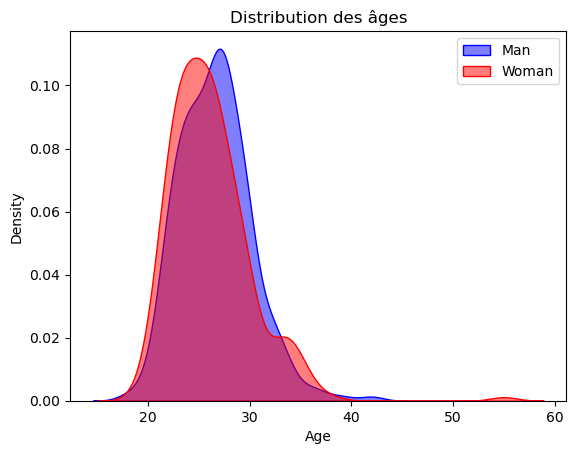

In [14]:
# Distribution des âges des participants 
df_age_men = df_men[["iid", "age"]].drop_duplicates().dropna()
df_age_women = df_women[["iid", "age"]].drop_duplicates().dropna()

sns.kdeplot(df_age_men["age"], fill=True, color='blue', label='Man', alpha=0.5)
sns.kdeplot(df_age_women["age"], fill=True, color='red', label="Woman", alpha=0.5)
plt.title("Distribution des âges")
plt.xlabel("Age")
plt.legend()

La majorité des participant sont jeunes, entre 20 et 30 ans. Femmes et hommes sont dans la même tranche d'âge.

---
## 4. Analyses Statistiques

<h3 style="color: red;">Ce que les participants ont déclaré préférer (Time1: avant les speed datings)</h3>

In [15]:
# Vérifier la consistence de ce que les femmes préfèrent
count = 0
df_temp = df_women[['iid', 'attr1_1', 'sinc1_1', 'intel1_1', 'fun1_1', 'amb1_1', 'shar1_1']].drop_duplicates(ignore_index=True)
for i in range(len(df_temp)):
    addi = df_temp.loc[i,['attr1_1', 'sinc1_1', 'intel1_1', 'fun1_1', 'amb1_1', 'shar1_1']].sum()
    if 0 != addi and ((101 < addi) or (99 > addi)):
        count += 1
        print(f"La somme {addi:.0f} n'est pas égale à 100")
print(f"Nombre de notations Femmes pas correctement remplies: {count}\n")

# Vérifier la consistence de ce que les hommes préfèrent
count = 0
df_temp = df_men[['iid', 'attr1_1', 'sinc1_1', 'intel1_1', 'fun1_1', 'amb1_1', 'shar1_1']].drop_duplicates(ignore_index=True)
for i in range(len(df_temp)):
    addi = df_temp.loc[i,['attr1_1', 'sinc1_1', 'intel1_1', 'fun1_1', 'amb1_1', 'shar1_1']].sum()
    if 0 != addi and ((101 < addi) or (99 > addi)):
        count += 1
        print(f"La somme {addi:.0f} n'est pas égale à 100")
print("Nombre de notations Hommes pas correctement remplies: ", count)

La somme 90 n'est pas égale à 100
La somme 110 n'est pas égale à 100
La somme 95 n'est pas égale à 100
Nombre de notations Femmes pas correctement remplies: 3

La somme 120 n'est pas égale à 100
La somme 148 n'est pas égale à 100
La somme 90 n'est pas égale à 100
La somme 90 n'est pas égale à 100
La somme 120 n'est pas égale à 100
La somme 90 n'est pas égale à 100
Nombre de notations Hommes pas correctement remplies:  6


La part des notations mal remplies étant marginale, elles n'invalident pas nos analyses. Leur impact étant quasiment nul.

,iid,attr1_1,sinc1_1,intel1_1,fun1_1,amb1_1,shar1_1
count,274.000000,269.000000,269.000000,269.000000,269.000000,269.000000,268.000000
mean,266.153285,18.020372,18.222230,20.971004,17.299108,12.818476,12.697836
std,159.093835,9.929864,6.977696,6.810653,5.637835,5.461131,5.912185
min,1.000000,0.000000,0.000000,2.000000,0.000000,0.000000,0.000000
25%,134.250000,12.240000,15.000000,18.000000,15.000000,10.000000,10.000000
50%,262.500000,15.090000,20.000000,20.000000,18.000000,15.000000,13.210000
75%,392.750000,20.000000,20.000000,25.000000,20.000000,16.670000,16.000000
max,530.000000,90.000000,60.000000,50.000000,40.000000,30.000000,30.000000


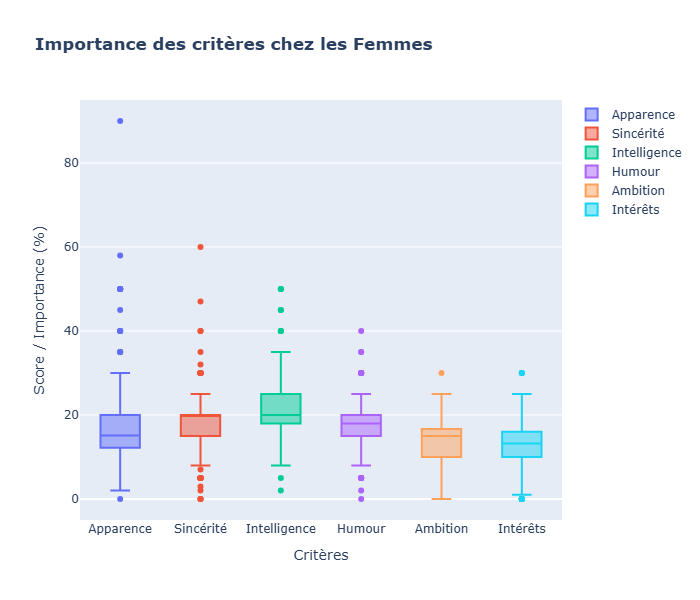

In [16]:
cols_attrib = ['attr1_1', 'sinc1_1', 'intel1_1', 'fun1_1', 'amb1_1', 'shar1_1']
df_temp = df_women[["iid"] + cols_attrib].drop_duplicates(ignore_index=True)
display(df_temp.describe())

# Distribution des critères chez les femmes
fig = go.Figure()
# Ajout de toutes les box plots
fig.add_trace(go.Box(y=df_temp["attr1_1"], name="Apparence"))
fig.add_trace(go.Box(y=df_temp["sinc1_1"], name="Sincérité"))
fig.add_trace(go.Box(y=df_temp["intel1_1"], name="Intelligence"))
fig.add_trace(go.Box(y=df_temp["fun1_1"], name="Humour"))
fig.add_trace(go.Box(y=df_temp["amb1_1"], name="Ambition"))
fig.add_trace(go.Box(y=df_temp["shar1_1"], name="Intérêts"))

fig.update_layout(
    title="<b>Importance des critères chez les Femmes</b>",
    xaxis_title="Critères",
    yaxis_title="Score / Importance (%)",
    height=600,
)

fig.show(renderer="png")

La dispersion autour des moyennes (principalement pour l'apparence) étant importante, Coéfficient de Variation CV elevé, on bascule vers la dispersion autour de la médiane (Coéfficient de Dispersion Quartile QCD) qui reste modérée.

En se basant sur les médianes et les écarts interquartiles, les femmes déclarent accorder plus d'importance à l'intelligence, puis la sincerité et l'humour. L'apparence physique ne vient qu'après.

,iid,attr1_1,sinc1_1,intel1_1,fun1_1,amb1_1,shar1_1
count,277.000000,275.000000,275.000000,275.000000,274.000000,273.000000,273.000000
mean,287.306859,27.248800,16.379600,19.387418,17.600839,8.823956,10.982271
std,159.479122,13.955701,7.318589,6.867587,6.696768,6.312040,6.887448
min,11.000000,6.670000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,158.000000,19.570000,10.000000,16.000000,15.000000,5.000000,5.000000
50%,287.000000,23.000000,17.000000,20.000000,18.000000,10.000000,10.000000
75%,424.000000,30.000000,20.000000,22.110000,20.000000,13.040000,15.560000
max,552.000000,100.000000,40.000000,42.860000,50.000000,53.000000,30.000000


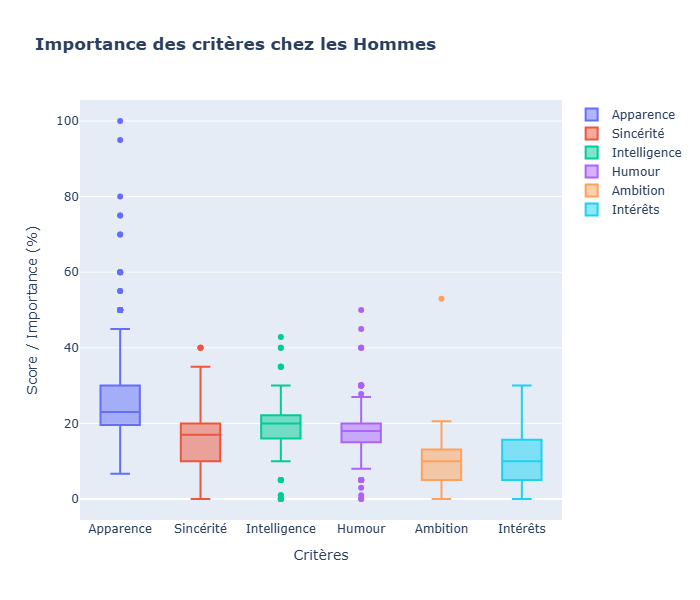

In [17]:
cols_attrib = ['attr1_1', 'sinc1_1', 'intel1_1', 'fun1_1', 'amb1_1', 'shar1_1']
df_temp = df_men[["iid"] + cols_attrib].drop_duplicates(ignore_index=True)
display(df_temp.describe())

# Distribution des critères chez les hommes
fig = go.Figure()
# Ajout de toutes les box plots
fig.add_trace(go.Box(y=df_temp["attr1_1"], name="Apparence"))
fig.add_trace(go.Box(y=df_temp["sinc1_1"], name="Sincérité"))
fig.add_trace(go.Box(y=df_temp["intel1_1"], name="Intelligence"))
fig.add_trace(go.Box(y=df_temp["fun1_1"], name="Humour"))
fig.add_trace(go.Box(y=df_temp["amb1_1"], name="Ambition"))
fig.add_trace(go.Box(y=df_temp["shar1_1"], name="Intérêts"))

fig.update_layout(
    title="<b>Importance des critères chez les Hommes</b>",
    xaxis_title="Critères",
    yaxis_title="Score / Importance (%)",
    height=600,
)

fig.show(renderer="png")

La dispersion autour des moyennes (principalement pour l'apparence) étant importante, Coéfficient de Variation CV elevé, on bascule vers la dispersion autour de la médiane (Coéfficient de Dispersion Quartile QCD) qui reste modérée.

En se basant sur les médianes et les écarts interquartiles, les hommes déclarent être principalement attirés par l'apparence. Viennent ensuite, l'intélligence, l'humour et puis la sincérité. Les hommes accordent moins d'importace à l'ambition et aux intérêts en commun.

In [18]:
# Analyser la différence des préférnces pour le critère "Apparence" entre hommes et femmes
men_attr = df_men[["iid"] + cols_attrib].drop_duplicates(ignore_index=True)['attr1_1']
women_attr = df_women[["iid"] + cols_attrib].drop_duplicates(ignore_index=True)['attr1_1']

# On utilise le test statistique U de Mann-Whitney
u_stat, p_val_mw = stats.mannwhitneyu(men_attr.dropna(), women_attr.dropna(), alternative="two-sided")
# Calcul de la taille de l'effet r (Rosenthal)
n1, n2 = len(men_attr), len(women_attr)
moy_u = n1 * n2 / 2
std_u = np.sqrt((n1 * n2 * (n1 + n2 +1))/12)
z_u = (u_stat - moy_u) / std_u
r_u = abs(z_u) / np.sqrt(n1 + n2)
print("Résultats du test u Mann-Whitney:")
print(f"P-value (Mann-Whitney) : {p_val_mw: .2e}")
print(f"U-statistic (Mann-Whitney): {u_stat}")
print(f"Score Z (Mann-Whitney): {z_u: .2f}")
print(f"Effet r (Mann-Whitney): {r_u: .2f}")

# Notre échantillon étant assez large pour pouvoir appliquer le Théorème Central Limite,
# Par conséquent, on peut aussi utiliser  le test t de Student pour comparer les moyennes
t_stat, p_val = stats.ttest_ind(men_attr.dropna(), women_attr.dropna())
print("\nRésultats du test t:")
print(f"P-value: {p_val}")
print(f"T-statistic: {t_stat}")

Résultats du test u Mann-Whitney:
P-value (Mann-Whitney) :  4.92e-27
U-statistic (Mann-Whitney): 56612.5
Score Z (Mann-Whitney):  9.99
Effet r (Mann-Whitney):  0.43

Résultats du test t:
P-value: 1.0643091582313154e-17
T-statistic: 8.869435922412281


La p-value étant très petite (p=10^-26 << 0.05), cela démontre une différence hautement significative entre les hommes et les femmes quant à l'importance accordée à l'apparence physique.

**L'apparence physique constitue un critère de sélection prioritaire de manière très marquée chez les hommes par rapport aux femmes dans ce jeu de données.**


---
### Corrélations entre les critères d'évaluation

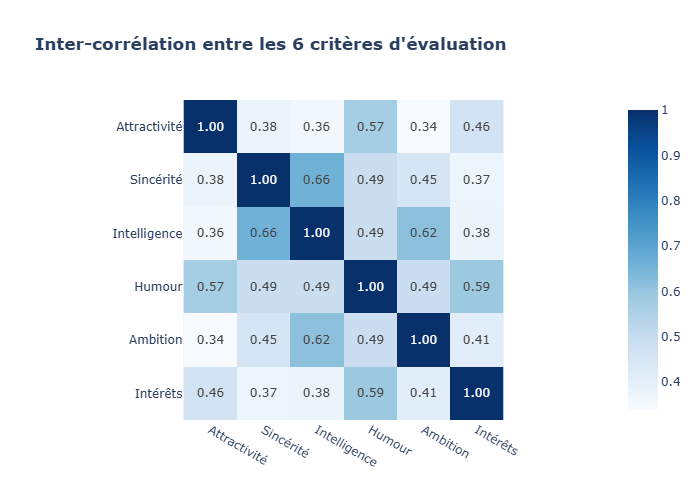

In [25]:
eval_cols = ["attr", "sinc", "intel", "fun", "amb", "shar"]
labels_dict = {
    "attr": "Attractivité",
    "sinc": "Sincérité",
    "intel": "Intelligence",
    "fun": "Humour",
    "amb": "Ambition",
    "shar": "Intérêts",
}

corr_inter = df[eval_cols].dropna().corr(method="spearman")
corr_inter.index = corr_inter.index.map(labels_dict)
corr_inter.columns = corr_inter.columns.map(labels_dict)

fig = px.imshow(
    corr_inter,
    text_auto=".2f",
    color_continuous_scale="Blues",
    title="<b>Inter-corrélation entre les 6 critères d'évaluation</b>",
)
fig.show(renderer='png')

La matrice de corrélation fait apparaître deux regroupements possibles parmi les six critères d'évaluation. Le premier rassemble l'attractivité, l'humour et les intérêts communs, tandis que le second regroupe la sincérité, l'intelligence et l'ambition. Ces regroupements sont suggérés par les corrélations relativement élevées entre les critères d'un même groupe, sans pour autant constituer deux dimensions totalement indépendantes.

---
<h3 style="color: green;">Ce que les participants préfèrent pour dire OUI (pendant les peed datings)</h3>

In [26]:
cols_rat = ['attr', 'sinc', 'intel', 'fun', 'amb', 'shar']
print("Taux de remplissage (%) des colonnes de notation pendant les speed datings --> Femmes")
display(round(df_women[cols_rat].notnull().mean() * 100, 2))
print("Taux de remplissage (%) des colonnes de notation pendant les speed datings --> Hommes")
display(round(df_men[cols_rat].notnull().mean() * 100, 2))

Taux de remplissage (%) des colonnes de notation pendant les speed datings --> Femmes


attr     97.59
sinc     96.89
intel    96.49
fun      95.63
amb      91.35
shar     86.23
dtype: float64

Taux de remplissage (%) des colonnes de notation pendant les speed datings --> Hommes


attr     97.59
sinc     96.49
intel    96.45
fun      96.02
amb      91.65
shar     88.29
dtype: float64

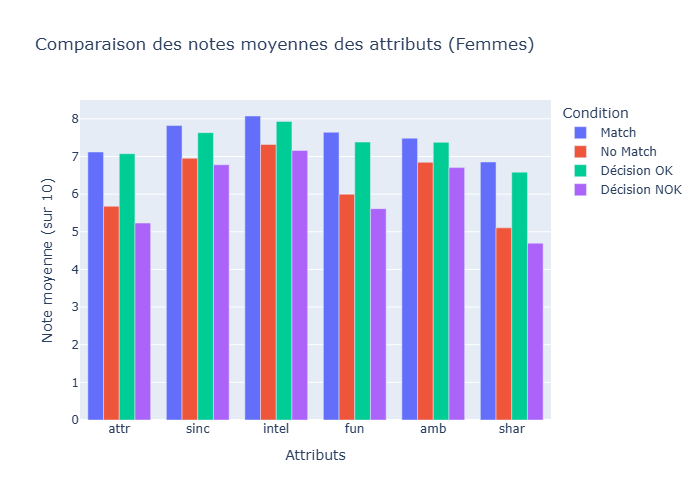

In [27]:
# Comment les femmes ont notés les hommes suivant match/no match, et décision OK/NOK
# Calculer les moyennes pour chaque attribut et chaque condition
data_means = []

for col in cols_rat:
    data_means.append({
        "Attribut": col,
        "Moyenne": df_women.loc[df_women["match"] == 1, col].mean(),
        "Condition": "Match",
    })
    data_means.append({
        "Attribut": col,
        "Moyenne": df_women.loc[df_women["match"] == 0, col].mean(),
        "Condition": "No Match",
    })
    data_means.append({
        "Attribut": col,
        "Moyenne": df_women.loc[df_women["dec"] == 1, col].mean(),
        "Condition": "Décision OK",
    })
    data_means.append({
        "Attribut": col,
        "Moyenne": df_women.loc[df_women["dec"] == 0, col].mean(),
        "Condition": "Décision NOK",
    })

df_plot = pd.DataFrame(data_means)

# 2. Graphique à barres vertical
fig = px.bar(
    df_plot,
    x="Attribut",
    y="Moyenne",
    color="Condition",
    barmode="group",  # mettre les barres côte à côte
    title=("Comparaison des notes moyennes des attributs (Femmes)"),
    labels={"Moyenne": "Note moyenne (sur 10)", "Attribut": "Attributs"},
    height=500,
)

fig.show(renderer="png")

On remarque que les moyennes, `en général`, des attributs quand il y a match ou décision OK sont elevées, spécialement pour l'intélligence et la sincértité. Par contre, ça nous permet pas de conclure sur les attributs qui sont **les plus impactants** sur cette décision (match ou OK).

On remarque aussi que quand il y a non match ou décision NOK, les attributs les moins bien notés sont le physique, l'humour et les intérêts en commun --> **à creuser!**

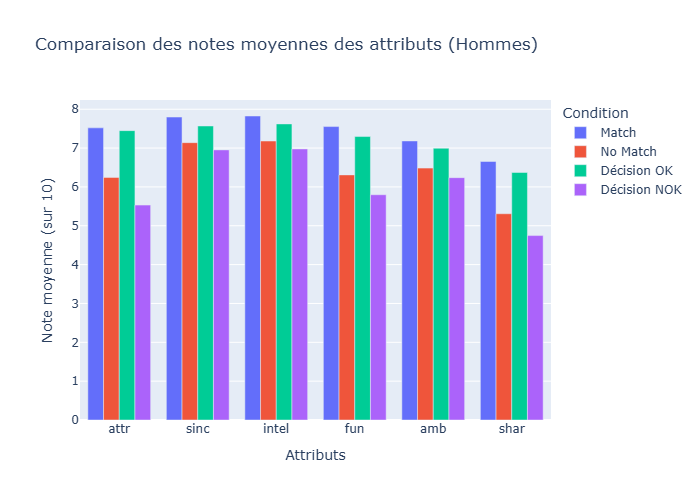

In [28]:
# Comment les hommes ont notés les femmes suivant match/no match, et décision OK/NOK
# Calculer les moyennes pour chaque attribut et chaque condition
data_means = []

for col in cols_rat:
    data_means.append({
        "Attribut": col,
        "Moyenne": df_men.loc[df_men["match"] == 1, col].mean(),
        "Condition": "Match",
    })
    data_means.append({
        "Attribut": col,
        "Moyenne": df_men.loc[df_men["match"] == 0, col].mean(),
        "Condition": "No Match",
    })
    data_means.append({
        "Attribut": col,
        "Moyenne": df_men.loc[df_men["dec"] == 1, col].mean(),
        "Condition": "Décision OK",
    })
    data_means.append({
        "Attribut": col,
        "Moyenne": df_men.loc[df_men["dec"] == 0, col].mean(),
        "Condition": "Décision NOK",
    })

df_plot = pd.DataFrame(data_means)

# 2. Graphique à barres vertical
fig = px.bar(
    df_plot,
    x="Attribut",
    y="Moyenne",
    color="Condition",
    barmode="group",  # mettre les barres côte à côte
    title=("Comparaison des notes moyennes des attributs (Hommes)"),
    labels={"Moyenne": "Note moyenne (sur 10)", "Attribut": "Attributs"},
    height=500,
)

fig.show(renderer="png")

On remarque que les moyennes, `en général`, des attributs quand il y a match ou décision OK sont elevées, spécialement pour l'apparence, la sincérité et l'intélligence. Par contre, ça nous permet pas de conclure sur les attributs qui sont **les plus impactants** sur cette décision (match ou OK).

On remarque aussi que quand il y a non match ou décision NOK, les attributs les moins bien notés sont le physique, l'humour et les intérêts en commun --> **à creuser!**

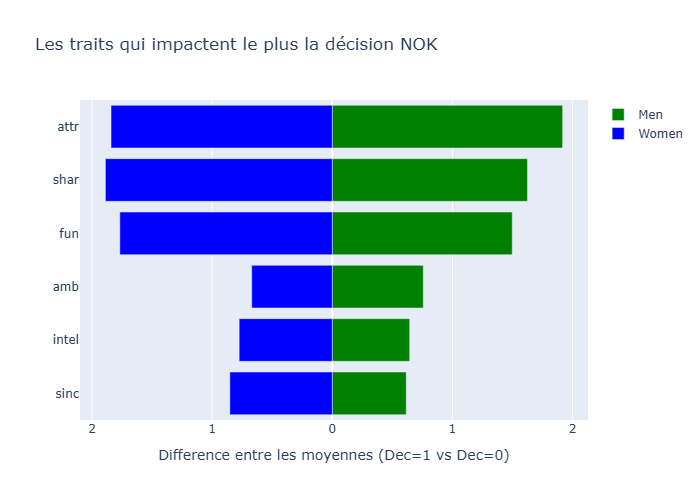

,Attribute,Male_Diff,Female_Diff
sinc,sinc,0.615549,0.852376
intel,intel,0.644072,0.774801
amb,amb,0.757340,0.670158
fun,fun,1.497859,1.767946
shar,shar,1.624452,1.888020
attr,attr,1.917000,1.841161


In [29]:
diff_men =  df_men.loc[df_men["dec"]==1][cols_rat].mean() - df_men.loc[df_men["dec"]==0][cols_rat].mean()
diff_women =  df_women.loc[df_women["dec"]==1][cols_rat].mean() - df_women.loc[df_women["dec"]==0][cols_rat].mean()
df_temp = pd.DataFrame({
    'Attribute': cols_rat,
    'Male_Diff': diff_men,
    'Female_Diff': diff_women
}).sort_values('Male_Diff')

fig = go.Figure()

# Hommes (Coté droit)
fig.add_trace(go.Bar(
    y=df_temp['Attribute'],
    x=df_temp['Male_Diff'],
    name='Men',
    orientation='h',
    marker_color='green',
    hovertemplate='Gap for Men: %{x:.2f}'
))

# Femmes (Coté gauche)
fig.add_trace(go.Bar(
    y=df_temp['Attribute'],
    x=df_temp['Female_Diff'] * -1,
    name='Women',
    orientation='h',
    marker_color='blue',
    customdata=df_temp['Female_Diff'],
    hovertemplate='Gap for Women: %{customdata:.2f}'
))

fig.update_layout(
    title='Les traits qui impactent le plus la décision NOK',
    xaxis_title='Difference entre les moyennes (Dec=1 vs Dec=0)',
    barmode='overlay',
    xaxis=dict(
        tickvals=[-4, -3, -2, -1, 0, 1, 2, 3, 4],
        ticktext=['4', '3', '2', '1', '0', '1', '2', '3', '4']
    )
)

fig.show(renderer='png')
display(df_temp)

Le graphe montre la différence entre les moyennes des traits/attributs quand la décision est OK et quand la décision est NOK pour les hommes et pour les femmes. On voit bien que toutes les moyennes baissent entre décision OK et décision NOK ce qui est normal.

Néanmoins, ce sont l'apparence, l'humour et les intérêts en commun qui baissent considérablement (de 1.5 à 1.9) quand la décision est NOK que ce soit pour les hommes ou pour les femmes. **Cela montre que ce sont l'apparence, l'humour et les intérêts en commun qui sont les traits discriminants (les plus impactants) pour la séléction et la décision**. 

`Il y a un décalage entre ce que les femmes ont déclaré préférer, et les traits réellement pris en compte lors de la décision --> à consolider.`

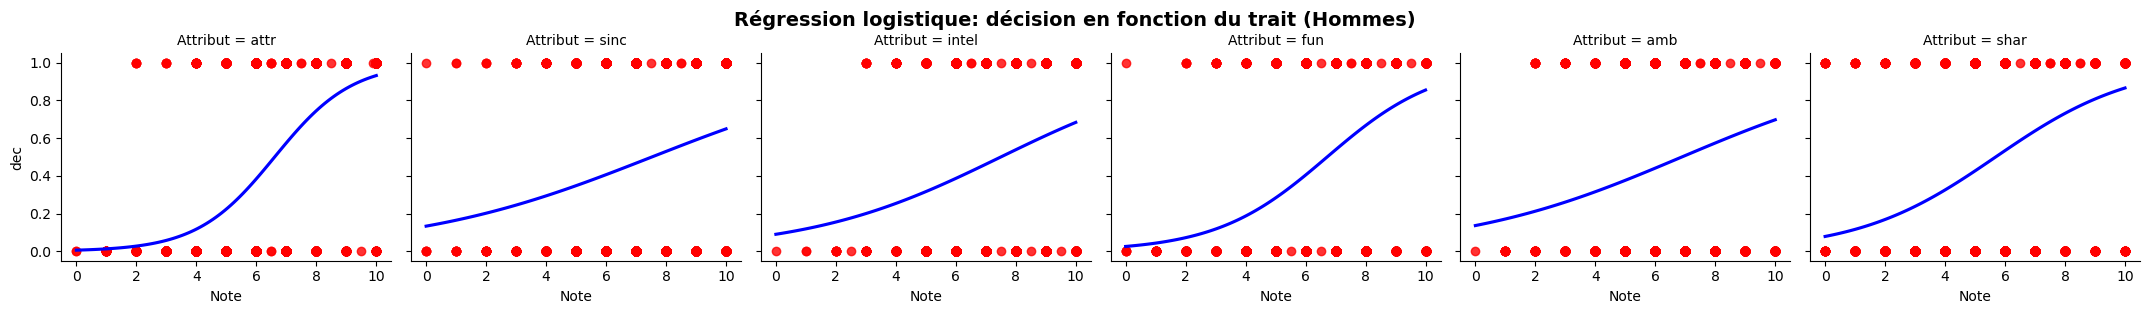

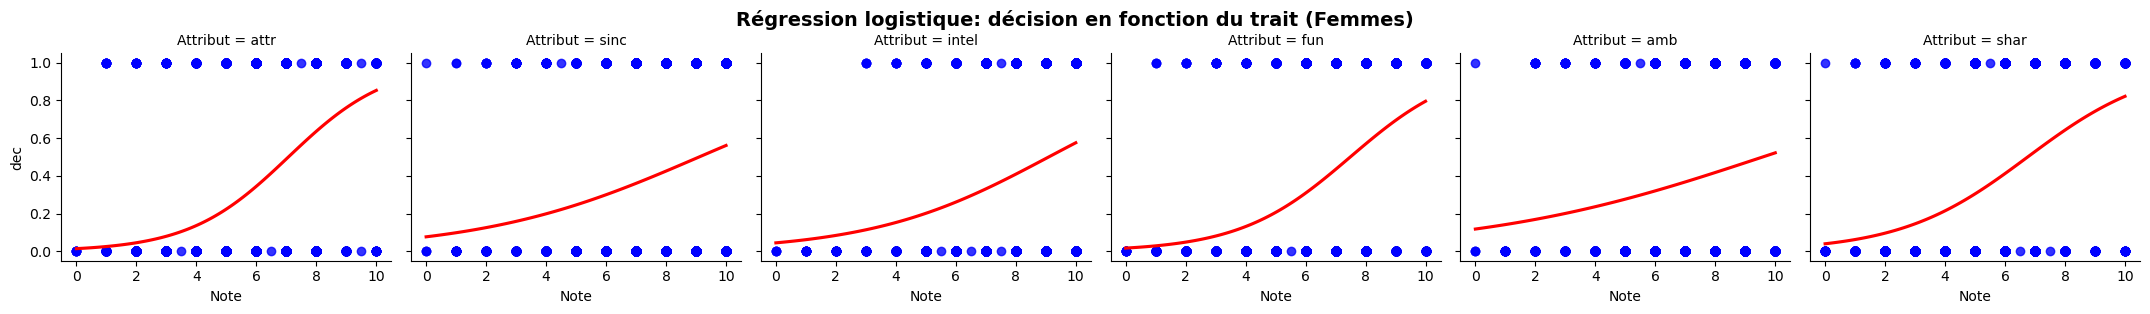

In [30]:
# Analyse de l'impact de chaque trait sur la décision via la régression logistique
#-------------- Hommes --------------
df_melted = df_men.melt(
    id_vars=["dec"],
    value_vars=cols_rat,
    var_name="Attribut",
    value_name="Note",
)
# Tracer tous les graphes de régression logistique
graph = sns.lmplot(
    data=df_melted,
    x="Note",
    y="dec",
    col="Attribut",
    logistic=True,
    ci=None,
    height=3,
    aspect=1.2,
    line_kws={"color": "blue"},
    scatter_kws={"color": "red"},
)
graph.fig.suptitle(
    "Régression logistique: décision en fonction du trait (Hommes)",
    y=1.03,
    fontsize=14,
    fontweight="bold",
)

plt.show()

#-------------- Femmes --------------
df_melted = df_women.melt(
    id_vars=["dec"],
    value_vars=cols_rat,
    var_name="Attribut",
    value_name="Note",
)
# Tracer tous les graphes de régression logistique
graph = sns.lmplot(
    data=df_melted,
    x="Note",
    y="dec",
    col="Attribut",
    logistic=True,
    ci=None,
    height=3,
    aspect=1.2,
    line_kws={"color": "red"},
    scatter_kws={"color": "blue"},
)
graph.fig.suptitle(
    "Régression logistique: décision en fonction du trait (Femmes)",
    y=1.03,
    fontsize=14,
    fontweight="bold",
)

plt.show()

Pour les deux sexes, les courbes de l'apparence, l'humour et les intérêts communs sont plus marquées et se rapprochent de la probabilité max (=1), contrairement aux autres traits.

Les graphes de régression logistique pour chaque trait viennent confirmer notre conclusion précédente. A savoir que les trait les plus impactants et influents sur la décision sont l'apparence, les intérêts en commun et l'humour que ce soit pour les femmes ou paour les hommes. Ce sont les trait pris en compte pour la décision d'avoir un second date.

Tableau de corrélation des femmes


,Critère,Coéff_Corrélation,P-value
0,Attractivité,0.457793,1.061664e-178
1,Humour,0.427782,7.354746e-154
2,Intérêts communs,0.415842,1.181361e-144
3,Intelligence,0.227289,9.530374e-42
4,Sincérité,0.221095,1.530430e-39
5,Ambition,0.174955,3.653913e-25


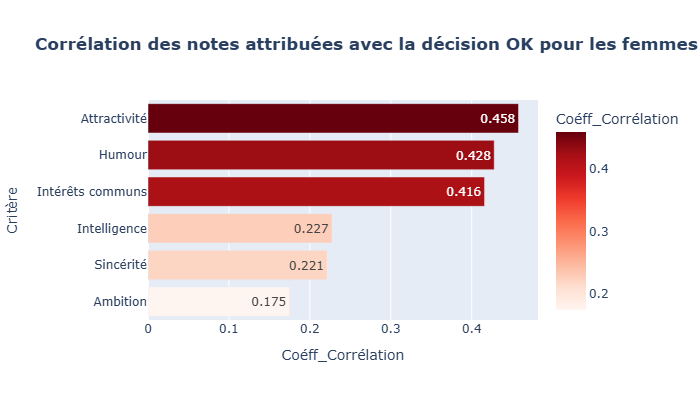

Tableau de corrélation des hommes


,Critère,Coéff_Corrélation,P-value
0,Attractivité,0.530118,7.025884e-259
1,Humour,0.409351,7.875517e-145
2,Intérêts communs,0.400072,7.778993e-138
3,Ambition,0.213300,3.844278e-38
4,Intelligence,0.211777,1.303373e-37
5,Sincérité,0.182311,3.765695e-28


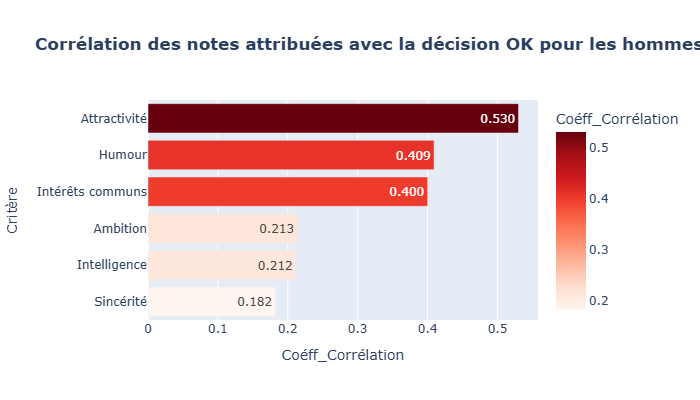

In [32]:
# On étudie maintenant la corrélation entre la décision et les différents traits
#------------ Femmes --------------------
cols_to_use = cols_rat + ["dec"]
# Nettoyage des valeurs manquantes sur ces variables
df_eval = df_women[cols_to_use].dropna()
# Dictionnaire de libellés explicites
labels_dict = {
    "attr": "Attractivité",
    "sinc": "Sincérité",
    "intel": "Intelligence",
    "fun": "Humour",
    "amb": "Ambition",
    "shar": "Intérêts communs",
}

# Calcul du coefficient de Spearman et de la p-value pour chaque critère avec 'dec'
results = []
for col in cols_rat:
    corr, p_val = stats.spearmanr(df_eval[col], df_eval["dec"])
    results.append(
        {
            "Critère": labels_dict[col],
            "Coéff_Corrélation": corr,
            "P-value": p_val,
        }
    )
df_corr_dec = (
    pd.DataFrame(results)
    .sort_values(by="Coéff_Corrélation", ascending=False)
    .reset_index(drop=True)
)

# Affichage du tableau de synthèse
print("Tableau de corrélation des femmes")
display(df_corr_dec)

# Graphique à barres des corrélations
fig = px.bar(
    df_corr_dec,
    x="Coéff_Corrélation",
    y="Critère",
    orientation="h",
    text_auto=".3f",
    color="Coéff_Corrélation",
    color_continuous_scale="Reds",
    title="<b>Corrélation des notes attribuées avec la décision OK pour les femmes</b>",
)
fig.update_layout(
    yaxis={"categoryorder": "total ascending"}, height=400, width=700
)
fig.show(renderer="png")

#------------ Hommes --------------------
# Nettoyage des valeurs manquantes sur ces variables
df_eval = df_men[cols_to_use].dropna()

# Calcul du coefficient de Spearman et de la p-value pour chaque critère avec 'dec'
results = []
for col in cols_rat:
    corr, p_val = stats.spearmanr(df_eval[col], df_eval["dec"])
    results.append(
        {
            "Critère": labels_dict[col],
            "Coéff_Corrélation": corr,
            "P-value": p_val,
        }
    )
df_corr_dec = (
    pd.DataFrame(results)
    .sort_values(by="Coéff_Corrélation", ascending=False)
    .reset_index(drop=True)
)

# Affichage du tableau de synthèse
print("Tableau de corrélation des hommes")
display(df_corr_dec)

# Graphique à barres des corrélations
fig = px.bar(
    df_corr_dec,
    x="Coéff_Corrélation",
    y="Critère",
    orientation="h",
    text_auto=".3f",
    color="Coéff_Corrélation",
    color_continuous_scale="Reds",
    title="<b>Corrélation des notes attribuées avec la décision OK pour les hommes</b>",
)
fig.update_layout(
    yaxis={"categoryorder": "total ascending"}, height=400, width=700
)
fig.show(renderer="png")

Chez les hommes, on voit bien que l'apparence est le trait, de loin, le plus corrélé avec la décision OUI. Ce qui a été déclaré avant les speed datings. Viennent ansuite, l'humour et les intérêts communs.

Chez les femmes, l'apparence physique est aussi le trait le plus correlée pour dire OUI à un participant. `Ceci confirme que malgré qu'elles ont déclaré ne pas accorder beaucoup d'importance à l'apparence physique, pendant les speed dating elles ont souvent décider avec les yeux`. Viennent ansuite, l'humour et les intérêts communs.

**Conclusion**: `L'aspect visuel reste le premier critère de sélection (décision OK) pour les femmes et pour les hommes`. Dans un contexte de speed dating de 4 min + de la surcharge de choix (plusieurs dates): l'humain simplifie ses décisions au profit du premier filtre visuel. Cela explique aussi le fait que l'humour et les intérêts rentrent comme un second critère de choix (rires, discours, ...). De l'autre côté, c'est tout a fait logique que les traits intelligence, ambition et sincérité ne soient pas un critère de choix. L'expérience s'est déroulé dans l'une des universités américaines les plus prestigieuses, iltelligence et ambition sont presque tout le temps bien notés. Quant à la sincérité, c'est difficile de l'évaluer durant 4 minutes.

---
## Mieux vaut-il être le premier ou le dernier rendez-vous de la soirée ?

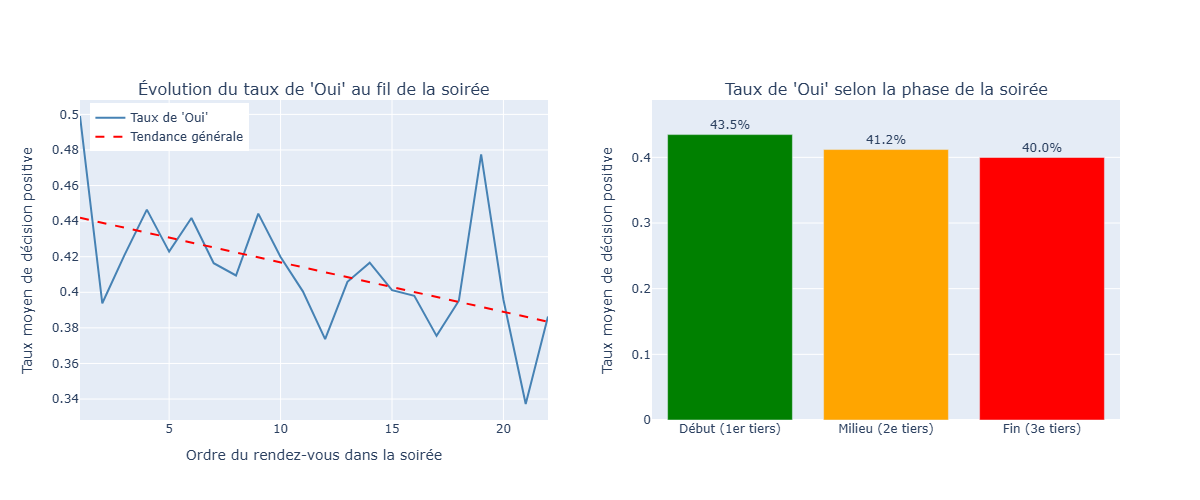

In [76]:
# Pour cette question, les deux variables sont nécessaires : la position du
# rendez-vous dans la soirée ('order') et la décision ('dec').
# Ces deux colonnes sont disponibles sur l'ensemble des lignes.
df_order = df.dropna(subset=['order', 'dec']).copy()

# Evolution du taux de 'Oui' suivant l'ordre des dates
order_rate = df_order.groupby("order")["dec"].mean().reset_index()
# Ligne de tendance (régression linéaire)
z = np.polyfit(order_rate["order"], order_rate["dec"], 1)
p = np.poly1d(z)
trend_y = p(order_rate["order"])
# Découpage de la soirée en trois tiers
max_order = df_order["order"].max()
df_order["phase"] = pd.cut(
    df_order["order"],
    bins=[0, max_order * 0.33, max_order * 0.66, max_order],
    labels=["Début\n(1er tiers)", "Milieu\n(2e tiers)", "Fin\n(3e tiers)"],
)
phase_rate = df_order.groupby("phase", observed=True)["dec"].mean().reset_index()

fig = make_subplots(
    rows=1, cols=2, subplot_titles=(
        "Évolution du taux de 'Oui' au fil de la soirée",
        "Taux de 'Oui' selon la phase de la soirée",
    )
)
# GRAPHIQUE 1 : Ligne d'évolution + Tendance
fig.add_trace(
    go.Scatter(
        x=order_rate["order"],
        y=order_rate["dec"],
        name="Taux de 'Oui'",
        marker=dict(color="steelblue", size=8),
        line=dict(color="steelblue"),
    ),
    row=1,
    col=1,
)
fig.add_trace(
    go.Scatter(
        x=order_rate["order"],
        y=trend_y,
        mode="lines",
        name="Tendance générale",
        line=dict(color="red", dash="dash"),
    ),
    row=1,
    col=1,
)
# Barres par phases de soirée
phase_colors = ["green", "orange", "red"]
fig.add_trace(
    go.Bar(
        x=phase_rate["phase"].astype(str),
        y=phase_rate["dec"],
        marker_color=phase_colors,
        text=phase_rate["dec"],
        texttemplate="%{text:.1%}",  # Format pourcentage à 1 décimale
        textposition="outside",
        showlegend=False,
    ),
    row=1,
    col=2,
)
# Mise en page globale
fig.update_layout(
    width=1200,
    height=500,
    legend=dict(x=0.01, y=0.99),
)
# Mise à jour des axes individuels
fig.update_xaxes(title_text="Ordre du rendez-vous dans la soirée", row=1, col=1)
fig.update_yaxes(title_text="Taux moyen de décision positive", row=1, col=1)
fig.update_yaxes(title_text="Taux moyen de décision positive", row=1, col=2)

fig.show(renderer='png')

**Il vaut mieux être rencontré en début de soirée, mais l'effet est modéré.** On observe un déclin léger et régulier du taux d'acceptation au fil de la soirée (une tendance à la baisse) :

- en découpant la soirée en trois tiers, le taux de « Oui » passe d'environ de **43.5 % au début à 40 % à la fin**, soit un écart de -3.5 points;

La direction est donc claire et cohérente entre les deux mesures, mais l'ampleur reste faible. 
<br>On ne parle donc pas d'un effet massif, mais d'une tendance descriptive régulière, compatible avec un phénomène de **fatigue décisionnelle** (*decision fatigue*) : au fil de rencontres répétées, la capacité d'évaluation se dégrade et les participants deviennent légèrement plus sélectifs. Ce biais cognitif est documenté en psychologie comportementale ; on le présente ici comme une hypothèse explicative et non comme une relation causale démontrée.

---
## Les gens peuvent-ils prédire leur valeur perçue sur le marché ?

On compare ici "comment le participant se perçoit lui même" avec "comment il est réellement noté par ses partenaires".

Auto-perception vs. Note réellement reçue (sur 10) :


,Auto_perception,Note_réelle_reçue,Surestimation
Attribut,,,
Attractivité,7.09,6.19,0.90
Sincérité,8.29,7.18,1.11
Intelligence,8.39,7.37,1.02
Humour,7.70,6.40,1.30
Ambition,7.58,6.78,0.80


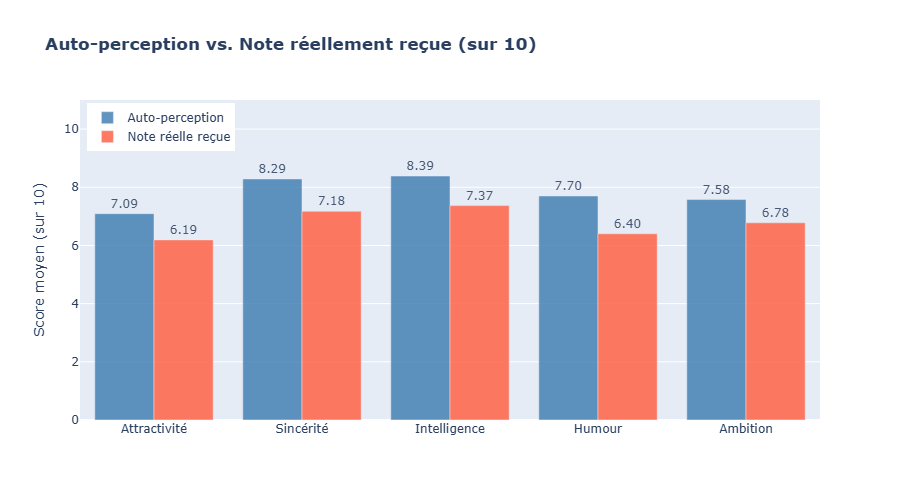

In [77]:
# Analyse de l'autoperception: critère3_1 --> évaluation dans le Time1 (avant les speed dating)
# attr3_1  = auto-évaluation : comment le participant pense que les autres le perçoivent
# attr_o = note réellement reçue de ses partenaires
# idem pour les autres critères (les intérêts partagés ne sont pas auto évalués)

# Calcul des moyennes "Auto-perception Vs Note réelle"
x_labels = ["Attractivité", "Sincérité", "Intelligence", "Humour", "Ambition"]
df_auto_percep = df[["attr3_1", "sinc3_1", "intel3_1", "fun3_1", "amb3_1"]+['iid']].drop_duplicates()
df_comparatif = pd.DataFrame({
    'Attribut'         : x_labels,
    'Auto_perception'  : [df_auto_percep['attr3_1'].mean(), df_auto_percep['sinc3_1'].mean(), df_auto_percep['intel3_1'].mean(), df_auto_percep['fun3_1'].mean(), df_auto_percep['amb3_1'].mean()],
    'Note_réelle_reçue': [df['attr_o'].mean(),  df['sinc_o'].mean(),  df['intel_o'].mean(),  df['fun_o'].mean(),  df['amb_o'].mean()]
})
df_comparatif['Surestimation'] = (df_comparatif['Auto_perception'] -
                                   df_comparatif['Note_réelle_reçue']).round(2)
        
print("Auto-perception vs. Note réellement reçue (sur 10) :")
display(df_comparatif.set_index('Attribut').round(2))

# Visualisation : graphique comparatif
fig = go.Figure()
# Barre Auto-perception
fig.add_trace(
    go.Bar(
        x=x_labels,
        y=df_comparatif['Auto_perception'],
        name="Auto-perception",
        marker_color="steelblue",
        opacity=0.85,
        text=df_comparatif['Auto_perception'],
        texttemplate="%{text:.2f}",  # Format à 2 décimales
        textposition="outside",
    )
)
# Barre Note réelle reçue
fig.add_trace(
    go.Bar(
        x=x_labels,
        y=df_comparatif['Note_réelle_reçue'],
        name="Note réelle reçue",
        marker_color="tomato",
        opacity=0.85,
        text=df_comparatif['Note_réelle_reçue'],
        texttemplate="%{text:.2f}",
        textposition="outside",
    )
)
# Mise en page
fig.update_layout(
    title="<b>Auto-perception vs. Note réellement reçue (sur 10)</b>",
    yaxis_title="Score moyen (sur 10)",
    barmode="group",  # Regroupe les barres côte à côte
    yaxis=dict(range=[0, 11]),  # Marge de 11 pour laisser la place aux textes
    width=900,
    height=500,
    legend=dict(x=0.01, y=0.99),
)

fig.show(renderer='png')

On observe une **surestimation** sur tous les attributs :

- Attractivité : surestimée de +0.90 point
- Sincérité : surestimée de +1.11 point
- Intelligence : surestimée de +1.02 point
- Humour : surestimée de +1.3 point
- Ambition : surestimée de +0.8 point

On a naturellement tendance à se percevoir plus positivement que les autres ne nous voient.

---
### Impact de l'origine raciale

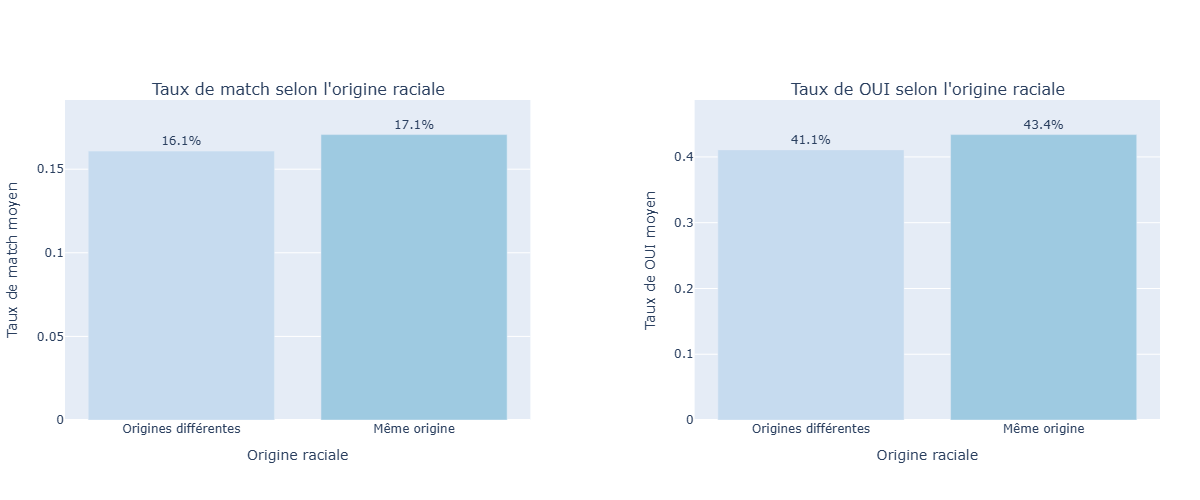

In [111]:
# Graphique 1 : Taux de match selon samerace
race_match = df.groupby('samerace')['match'].mean().reset_index()
race_match['samerace'] = race_match['samerace'].map({
    0: 'Origines différentes',
    1: 'Même origine'
})

fig1 = px.bar(
    race_match,
    x='samerace',
    y='match',
    color='samerace',
    color_discrete_sequence=px.colors.sequential.Blues[2:4],
    text=race_match['match'].map(lambda x: f'{x:.1%}'),
    labels={
        'samerace': 'Origine raciale',
        'match': 'Taux de match moyen'
    },
    title="Taux de match selon l'origine raciale partagée"
)
fig1.update_traces(
    textposition='outside',
    hovertemplate='%{x}<br>Taux de match : %{y:.1%}<extra></extra>'
)
fig1.update_layout(
    showlegend=False,
    yaxis_tickformat='.0%',
    yaxis_title='Taux de match moyen',
    xaxis_title='Origine raciale',
    template='plotly_white'
)


# Graphique 2 : Taux de décision OK selon samerace
race_dec = df.groupby('samerace')['dec'].mean().reset_index()
race_dec['samerace'] = race_dec['samerace'].map({
    0: 'Origines différentes',
    1: 'Même origine'
})

fig2 = px.bar(
    race_dec,
    x='samerace',
    y='dec',
    color='samerace',
    color_discrete_sequence=px.colors.sequential.Blues[2:4],
    text=race_dec['dec'].map(lambda x: f'{x:.1%}'),
    labels={
        'samerace': 'Origine raciale',
        'dec': 'Taux de OUI moyen'
    },
    title="Taux de OUI selon l'origine raciale partagée"
)
fig2.update_traces(
    textposition='outside',
    hovertemplate='%{x}<br>Taux de OUI : %{y:.1%}<extra></extra>'
)
fig2.update_layout(
    showlegend=False,
    yaxis_tickformat='.0%',
    yaxis_title='Taux de OUI moyen',
    xaxis_title='Origine raciale',
    template='plotly_white'
)

# Affichage côte à côte
fig = make_subplots(
    rows=1,
    cols=2,
    subplot_titles=[
        "Taux de match selon l'origine raciale",
        "Taux de OUI selon l'origine raciale"
    ],
    horizontal_spacing=0.15
)

# Ajouter les barres du premier graphique
for trace in fig1.data:
    fig.add_trace(trace, row=1, col=1)

# Ajouter les barres du deuxième graphique
for trace in fig2.data:
    fig.add_trace(trace, row=1, col=2)

fig.update_layout(
    title_x=0.5,
    height=500,
    width=1200,
    showlegend=False,
    margin=dict(t=100, b=80, l=60, r=40)
)

fig.update_yaxes(title_text='Taux de match moyen', row=1, col=1)
fig.update_yaxes(title_text='Taux de OUI moyen', row=1, col=2)
fig.update_xaxes(title_text='Origine raciale', row=1, col=1)
fig.update_xaxes(title_text="Origine raciale", row=1, col=2)

fig.show(renderer='png')

L'origine raciale joue un rôle marginal dans la décision du oui et du match(+1% à 2%). Cela suggère que les algorithmes de matching basés sur la proximité démographique ne seront pas d'une grande éfficacité.

---
## Les préferences au fil du temps

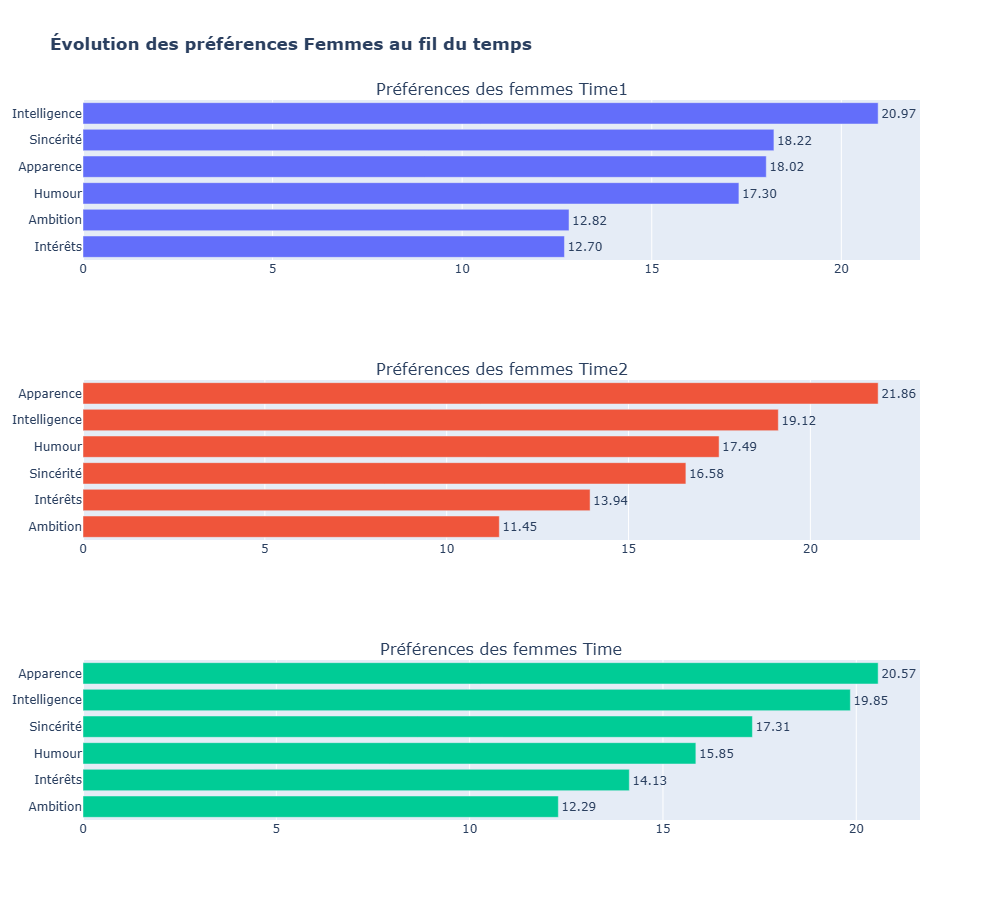

In [132]:
# Comment les femmes classent les critères après l'expérience?
# Comparaison des moyennes attribuées aux attributs/critères entre les trois phases
# Time1: avant, Time2: le lendemain, Time3: 3-4 semaines après

# Dictionnaire de mapping
mapping_noms_1 = {
    "attr1_1": "Apparence",
    "sinc1_1": "Sincérité",
    "intel1_1": "Intelligence",
    "fun1_1": "Humour",
    "amb1_1": "Ambition",
    "shar1_1": "Intérêts",
}

mapping_noms_2 = {
    "attr1_2": "Apparence",
    "sinc1_2": "Sincérité",
    "intel1_2": "Intelligence",
    "fun1_2": "Humour",
    "amb1_2": "Ambition",
    "shar1_2": "Intérêts",
}

mapping_noms_3 = {
    "attr1_3": "Apparence",
    "sinc1_3": "Sincérité",
    "intel1_3": "Intelligence",
    "fun1_3": "Humour",
    "amb1_3": "Ambition",
    "shar1_3": "Intérêts",
}
df_temp1 = df_women[['iid', 'attr1_1', 'sinc1_1', 'intel1_1', 'fun1_1', 'amb1_1', 'shar1_1']].drop_duplicates(ignore_index=True)
df_temp1 = df_temp1.drop(columns="iid").mean().reset_index()
df_temp1.columns = ["Attribut", "Moyenne"] 
df_temp1["Attribut"] = df_temp1["Attribut"].replace(mapping_noms_1)
df_temp1 = df_temp1.sort_values(by="Moyenne")

df_temp2 = df_women[['iid', 'attr1_2', 'sinc1_2', 'intel1_2', 'fun1_2', 'amb1_2', 'shar1_2']].drop_duplicates(ignore_index=True)
df_temp2 = df_temp2.drop(columns="iid").mean().reset_index()
df_temp2.columns = ["Attribut", "Moyenne"]  
df_temp2["Attribut"] = df_temp2["Attribut"].replace(mapping_noms_2)
df_temp2 = df_temp2.sort_values(by="Moyenne")

df_temp3 = df_women[['iid', 'attr1_3', 'sinc1_3', 'intel1_3', 'fun1_3', 'amb1_3', 'shar1_3']].drop_duplicates(ignore_index=True)
df_temp3 = df_temp3.drop(columns="iid").mean().reset_index()
df_temp3.columns = ["Attribut", "Moyenne"] 
df_temp3["Attribut"] = df_temp3["Attribut"].replace(mapping_noms_3)
df_temp3 = df_temp3.sort_values(by="Moyenne")

fig = make_subplots(
    rows=3, cols=1, subplot_titles=(
        "Préférences des femmes Time1",
        "Préférences des femmes Time2",
        "Préférences des femmes Time"
    )
)

# Graphique 1
fig.add_trace(
    go.Bar(
        x=df_temp1["Moyenne"],
        y=df_temp1["Attribut"],
        orientation="h",
        text=df_temp1["Moyenne"],
        texttemplate="%{text:.2f}",
        textposition="outside",
        showlegend=False,
    ),
    row=1,
    col=1,
)
# Graphique 2
fig.add_trace(
    go.Bar(
        x=df_temp2["Moyenne"],
        y=df_temp2["Attribut"],
        orientation="h",
        text=df_temp2["Moyenne"],
        texttemplate="%{text:.2f}",
        textposition="outside",
        showlegend=False,
    ),
    row=2,
    col=1,
)
# Graphique 3
fig.add_trace(
    go.Bar(
        x=df_temp3["Moyenne"],
        y=df_temp3["Attribut"],
        orientation="h",
        text=df_temp3["Moyenne"],
        texttemplate="%{text:.2f}",
        textposition="outside",
        showlegend=False,
    ),
    row=3,
    col=1,
)

fig.update_layout(
    height=900,
    width=1000,
    title_text="<b>Évolution des préférences Femmes au fil du temps</b>",
)

fig.show(renderer="png")

Après l'expérience, les femmes classent l'apparence en critère numéro 1, spécialement au lendemain de l'expérience. Le critère visuel était bien le plus impactant pour la décision positive.

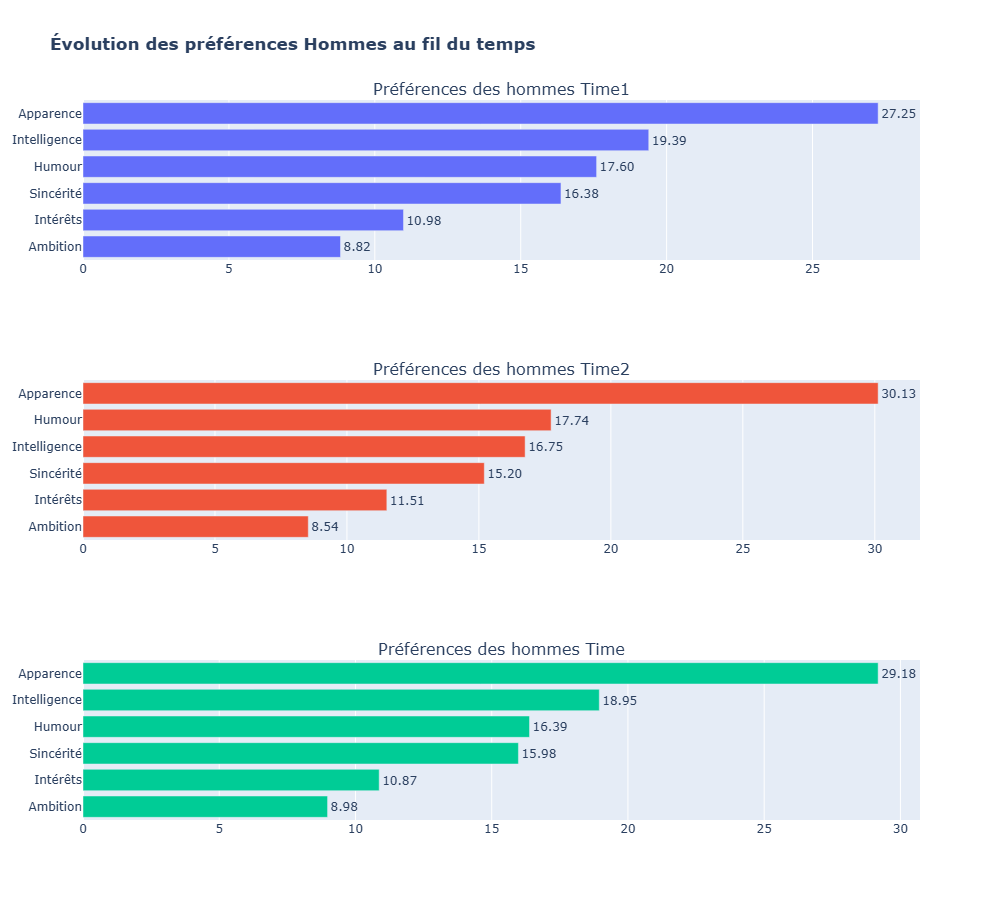

In [130]:
# Comment les hommes classent les critères après l'expérience?
# Comparaison des moyennes attribuées aux attributs/critères entre les trois phases
# Time1: avant, Time2: le lendemain, Time3: 3-4 semaines après

# Dictionnaire de mapping
mapping_noms_1 = {
    "attr1_1": "Apparence",
    "sinc1_1": "Sincérité",
    "intel1_1": "Intelligence",
    "fun1_1": "Humour",
    "amb1_1": "Ambition",
    "shar1_1": "Intérêts",
}

mapping_noms_2 = {
    "attr1_2": "Apparence",
    "sinc1_2": "Sincérité",
    "intel1_2": "Intelligence",
    "fun1_2": "Humour",
    "amb1_2": "Ambition",
    "shar1_2": "Intérêts",
}

mapping_noms_3 = {
    "attr1_3": "Apparence",
    "sinc1_3": "Sincérité",
    "intel1_3": "Intelligence",
    "fun1_3": "Humour",
    "amb1_3": "Ambition",
    "shar1_3": "Intérêts",
}
df_temp1 = df_men[['iid', 'attr1_1', 'sinc1_1', 'intel1_1', 'fun1_1', 'amb1_1', 'shar1_1']].drop_duplicates(ignore_index=True)
df_temp1 = df_temp1.drop(columns="iid").mean().reset_index()
df_temp1.columns = ["Attribut", "Moyenne"] 
df_temp1["Attribut"] = df_temp1["Attribut"].replace(mapping_noms_1)
df_temp1 = df_temp1.sort_values(by="Moyenne")

df_temp2 = df_men[['iid', 'attr1_2', 'sinc1_2', 'intel1_2', 'fun1_2', 'amb1_2', 'shar1_2']].drop_duplicates(ignore_index=True)
df_temp2 = df_temp2.drop(columns="iid").mean().reset_index()
df_temp2.columns = ["Attribut", "Moyenne"]  
df_temp2["Attribut"] = df_temp2["Attribut"].replace(mapping_noms_2)
df_temp2 = df_temp2.sort_values(by="Moyenne")

df_temp3 = df_men[['iid', 'attr1_3', 'sinc1_3', 'intel1_3', 'fun1_3', 'amb1_3', 'shar1_3']].drop_duplicates(ignore_index=True)
df_temp3 = df_temp3.drop(columns="iid").mean().reset_index()
df_temp3.columns = ["Attribut", "Moyenne"] 
df_temp3["Attribut"] = df_temp3["Attribut"].replace(mapping_noms_3)
df_temp3 = df_temp3.sort_values(by="Moyenne")

fig = make_subplots(
    rows=3, cols=1, subplot_titles=(
        "Préférences des hommes Time1",
        "Préférences des hommes Time2",
        "Préférences des hommes Time"
    )
)

# Graphique 1
fig.add_trace(
    go.Bar(
        x=df_temp1["Moyenne"],
        y=df_temp1["Attribut"],
        orientation="h",
        text=df_temp1["Moyenne"],
        texttemplate="%{text:.2f}",
        textposition="outside",
        showlegend=False,
    ),
    row=1,
    col=1,
)
# Graphique 2
fig.add_trace(
    go.Bar(
        x=df_temp2["Moyenne"],
        y=df_temp2["Attribut"],
        orientation="h",
        text=df_temp2["Moyenne"],
        texttemplate="%{text:.2f}",
        textposition="outside",
        showlegend=False,
    ),
    row=2,
    col=1,
)
# Graphique 3
fig.add_trace(
    go.Bar(
        x=df_temp3["Moyenne"],
        y=df_temp3["Attribut"],
        orientation="h",
        text=df_temp3["Moyenne"],
        texttemplate="%{text:.2f}",
        textposition="outside",
        showlegend=False,
    ),
    row=3,
    col=1,
)

fig.update_layout(
    height=900,
    width=1000,
    title_text="<b>Évolution des préférences Hommes au fil du temps</b>",
)

fig.show(renderer="png")

Le classement des hommes reste dominé par l'apparence. Il n'y a pas eu de changement notable. Clair et assumé!

---
## 5. Recommandations Stratégiques

**1. Valoriser le contenu visuel des profils**  
L'attractivité est le premier filtre de sélection . Tinder devrait continuer à mettre les photos au cœur de l'expérience et proposer des outils d'aide à la sélection de la meilleure photo.

**2. Renforcer l'algorithme de matching par les passions**  
Les intérêts communs ont un impact sur le match. La prise en compte des centres d'intérêt dans l'algorithme de recommendation des profils permettrait d'améliorer le taux de match.

**3. Limiter le volume de profils par session**  
La fatigue décisionnelle se traduit par un déclin léger mais régulier du taux d'acceptation au fil de la soirée. Introduire une limite quotidienne de swipes ou des pauses suggérées pourrait préserver la qualité des décisions et limiter ce phénomène d'évaluation dégradée.

**4. Travailler la perception de soi des utilisateurs**  
L'auopecerption surestimée peut créer des attentes irréalistes et génère des frustrations. Des fonctionnalités de feedback anonymisé ou de calibration du profil pourraient aider les utilisateurs à mieux se positionner sur le marché.